# OrbitalRoute AI — Notebook de análisis matemático

**Objetivo:** explorar una base didáctica de posiciones satelitales, calcular distancias, construir un grafo de conectividad y buscar una ruta de menor costo.

> **Importante:** el archivo CSV incluido es una base **sintética para fines académicos**. Las posiciones se generan con un modelo circular simplificado y las variables de latencia, pérdida y capacidad son simuladas. No son telemetría real ni datos orbitales oficiales. Para un estudio real, sustituye la base por TLE y propaga las órbitas con SGP4.


## 1. Instalar dependencias
En la terminal de Visual Studio Code ejecuta: `python -m pip install pandas numpy matplotlib networkx jupyter`.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
df = pd.read_csv("OrbitalRoute_Base.csv")
df.head()


,satellite_id,time_min,x_km,y_km,z_km,vx_km_s,vy_km_s,vz_km_s,latency_ms_synthetic,packet_loss_pct_synthetic,capacity_mbps_synthetic,data_type
0,SAT-01,0.0,6.921000e+03,0.00000,23.840320,-0.000000,7.500000e+00,0.058804,12.457076,0.540004,715.352419,SINTETICO_DIDACTICO
1,SAT-02,0.0,5.993762e+03,3460.50000,53.467168,-3.750000,6.495191e+00,0.053715,14.610847,0.312241,657.069633,SINTETICO_DIDACTICO
2,SAT-03,0.0,3.460500e+03,5993.76182,79.450317,-6.495191,3.750000e+00,0.044966,14.591761,0.720939,682.929892,SINTETICO_DIDACTICO
3,SAT-04,0.0,4.237890e-13,6921.00000,100.019059,-7.500000,4.592425e-16,0.033152,14.320434,1.019849,700.992366,SINTETICO_DIDACTICO
4,SAT-05,0.0,-3.460500e+03,5993.76182,113.771666,-6.495191,-3.750000e+00,0.019079,12.099046,1.081810,712.557818,SINTETICO_DIDACTICO


## 2. Revisar la base de datos

In [3]:
print("Dimensiones:", df.shape)
print("\\nTipos de datos:")
print(df.dtypes)
print("\\nValores faltantes:")
print(df.isna().sum())
print("\\nSatélites:", df["satellite_id"].nunique())
print("\\nInstantes:", sorted(df["time_min"].unique()))


Dimensiones: (120, 12)
\nTipos de datos:
satellite_id                     str
time_min                     float64
x_km                         float64
y_km                         float64
z_km                         float64
vx_km_s                      float64
vy_km_s                      float64
vz_km_s                      float64
latency_ms_synthetic         float64
packet_loss_pct_synthetic    float64
capacity_mbps_synthetic      float64
data_type                        str
dtype: object
\nValores faltantes:
satellite_id                 0
time_min                     0
x_km                         0
y_km                         0
z_km                         0
vx_km_s                      0
vy_km_s                      0
vz_km_s                      0
latency_ms_synthetic         0
packet_loss_pct_synthetic    0
capacity_mbps_synthetic      0
data_type                    0
dtype: int64
\nSatélites: 12
\nInstantes: [np.float64(0.0), np.float64(2.0), np.float64(4.0), np.float64(6.0

In [4]:
df[[
    "x_km", "y_km", "z_km",
    "latency_ms_synthetic",
    "packet_loss_pct_synthetic",
    "capacity_mbps_synthetic"
]].describe().round(2)


,x_km,y_km,z_km,latency_ms_synthetic,packet_loss_pct_synthetic,capacity_mbps_synthetic
count,120.00,120.00,120.00,120.00,120.00,120.00
mean,-0.00,-0.00,70.24,13.84,0.80,688.54
std,4914.41,4914.41,47.81,1.99,0.25,22.83
min,-6921.00,-6921.00,-61.02,8.92,0.23,641.24
25%,-4887.12,-4887.12,38.90,12.50,0.64,671.11
50%,-0.00,0.00,84.85,14.10,0.79,688.58
75%,4887.12,4887.12,110.73,14.93,0.93,701.81
max,6921.00,6921.00,120.00,18.74,1.53,756.06


## 3. Visualizar las posiciones en el plano XY

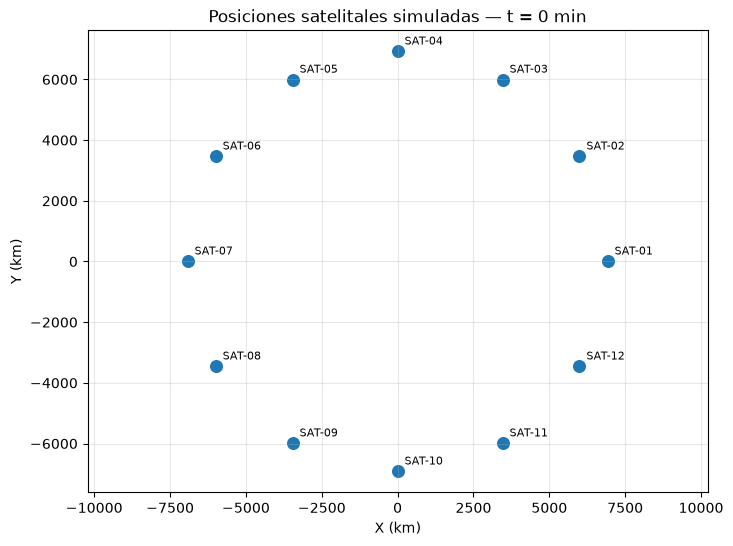

In [5]:
t0 = df["time_min"].min()
sample = df[df["time_min"] == t0]

plt.figure(figsize=(8, 6))
plt.scatter(sample["x_km"], sample["y_km"], s=70)
for _, row in sample.iterrows():
    plt.annotate(row["satellite_id"], (row["x_km"], row["y_km"]),
                 xytext=(5, 5), textcoords="offset points", fontsize=8)
plt.xlabel("X (km)")
plt.ylabel("Y (km)")
plt.title(f"Posiciones satelitales simuladas — t = {t0:.0f} min")
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.show()


## 4. Calcular distancias entre satélites

In [6]:
def distancia_3d(a, b):
    return np.sqrt(
        (a["x_km"] - b["x_km"])**2 +
        (a["y_km"] - b["y_km"])**2 +
        (a["z_km"] - b["z_km"])**2
    )

records = sample.to_dict("records")
distancias = []
for i in range(len(records)):
    for j in range(i + 1, len(records)):
        distancias.append({
            "satellite_1": records[i]["satellite_id"],
            "satellite_2": records[j]["satellite_id"],
            "distance_km": distancia_3d(records[i], records[j])
        })

dist_df = pd.DataFrame(distancias).sort_values("distance_km")
dist_df.head(10)


,satellite_1,satellite_2,distance_km
45,SAT-06,SAT-07,3582.573875
38,SAT-05,SAT-06,3582.578245
51,SAT-07,SAT-08,3582.587679
30,SAT-04,SAT-05,3582.599619
10,SAT-01,SAT-12,3582.610893
56,SAT-08,SAT-09,3582.615958
21,SAT-03,SAT-04,3582.632268
60,SAT-09,SAT-10,3582.651135
11,SAT-02,SAT-03,3582.667444
63,SAT-10,SAT-11,3582.683784


## 5. Construir el grafo de conectividad

In [7]:
UMBRAL_KM = 4000

G = nx.Graph()
for _, row in sample.iterrows():
    G.add_node(row["satellite_id"])

for _, edge in dist_df.iterrows():
    if edge["distance_km"] <= UMBRAL_KM:
        G.add_edge(
            edge["satellite_1"],
            edge["satellite_2"],
            distance_km=float(edge["distance_km"])
        )

print("Nodos:", G.number_of_nodes())
print("Enlaces:", G.number_of_edges())
print("¿Es conexo?:", nx.is_connected(G))
print("Grados:", dict(G.degree()))


Nodos: 12
Enlaces: 12
¿Es conexo?: True
Grados: {'SAT-01': 2, 'SAT-02': 2, 'SAT-03': 2, 'SAT-04': 2, 'SAT-05': 2, 'SAT-06': 2, 'SAT-07': 2, 'SAT-08': 2, 'SAT-09': 2, 'SAT-10': 2, 'SAT-11': 2, 'SAT-12': 2}


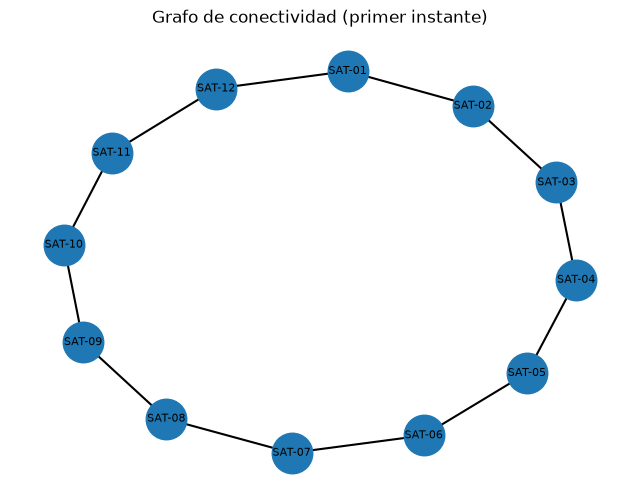

In [8]:
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G, seed=7)
nx.draw_networkx(G, pos, with_labels=True, node_size=850,
                 font_size=8, width=1.5)
plt.title("Grafo de conectividad (primer instante)")
plt.axis("off")
plt.show()


## 6. Asignar costo y buscar una ruta

In [9]:
lookup = sample.set_index("satellite_id")

for u, v, data in G.edges(data=True):
    dist = data["distance_km"]
    latency = (
        lookup.loc[u, "latency_ms_synthetic"] +
        lookup.loc[v, "latency_ms_synthetic"]
    ) / 2
    loss = (
        lookup.loc[u, "packet_loss_pct_synthetic"] +
        lookup.loc[v, "packet_loss_pct_synthetic"]
    ) / 2

    
    data["cost"] = 0.001 * dist + 0.05 * latency + 0.2 * loss

origen = "SAT-01"
destino = "SAT-07"

try:
    ruta = nx.dijkstra_path(G, origen, destino, weight="cost")
    costo_total = nx.dijkstra_path_length(G, origen, destino, weight="cost")
    print("Ruta:", " -> ".join(ruta))
    print("Costo total:", round(costo_total, 3))
except nx.NetworkXNoPath:
    print("No existe una ruta entre esos nodos con el umbral actual.")


Ruta: SAT-01 -> SAT-02 -> SAT-03 -> SAT-04 -> SAT-05 -> SAT-06 -> SAT-07
Costo total: 26.515


## 7. Analizar las variables simuladas

,latency_ms_synthetic,packet_loss_pct_synthetic,capacity_mbps_synthetic
time_min,,,
0.0,13.95,0.81,690.01
2.0,13.90,0.73,691.15
4.0,13.34,0.74,691.43
6.0,14.13,0.78,682.91
8.0,13.52,0.78,691.23
10.0,13.99,0.81,686.25
12.0,12.96,0.89,695.17
14.0,14.33,0.83,681.04
16.0,14.34,0.82,685.81


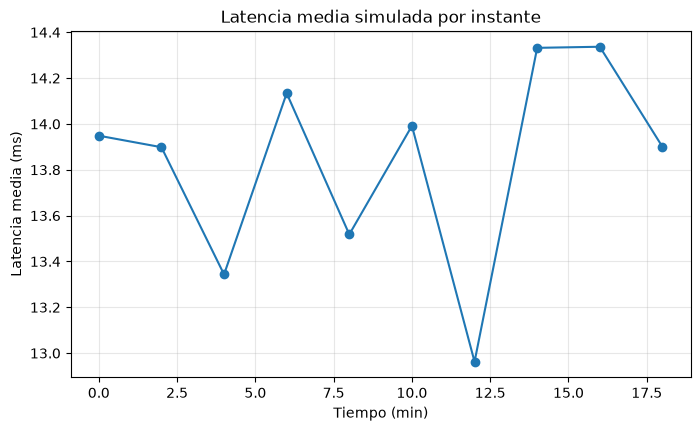

In [10]:
promedios = df.groupby("time_min")[[
    "latency_ms_synthetic",
    "packet_loss_pct_synthetic",
    "capacity_mbps_synthetic"
]].mean()

display(promedios.round(2))

plt.figure(figsize=(8, 4.5))
plt.plot(promedios.index, promedios["latency_ms_synthetic"], marker="o")
plt.xlabel("Tiempo (min)")
plt.ylabel("Latencia media (ms)")
plt.title("Latencia media simulada por instante")
plt.grid(True, alpha=0.3)
plt.show()


## 8. Conclusión para completar
La base permite practicar el cálculo de distancias, la construcción de grafos y la búsqueda de rutas mediante Dijkstra. Los resultados describen únicamente el escenario sintético construido. Para afirmar que OrbitalRoute AI mejora el rendimiento de una red real, se necesitarían datos orbitales y de comunicación verificables, escenarios comparables y métricas experimentales.

## 9. Fuentes y documentación
- NetworkX: https://networkx.org/documentation/stable/
- CelesTrak (datos orbitales TLE): https://celestrak.org/
- Documentación de pandas: https://pandas.pydata.org/docs/
- Documentación de Matplotlib: https://matplotlib.org/stable/